# Supplementary Figure 12

Functional allocation and leading-species attribution (v30). Panel a shows how much accepted feature intensity is allocated to a KEGG ortholog in each acquisition of three cohorts; panels b-f show how stable and how complete the leading-species labels of functions are, in healthy stool (b, e) and in CapScan (c, d, f). All panels use direct peptide assignment; the original protein-grouping series of panels e and f was removed in v30.

Run from the repository root: `python paper.py build SFig12`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()

All six panels share one canvas, as in the v30 build. The next cell reads the inputs (sha256 checked). Each panel section prints the values it draws; the canvas is drawn under `Composite`.

In [2]:
from IPython.display import Image, display
SD5 = REPO / "source_data" / "Fig5"     # contributor_cells.tsv lives under Fig5
t = panels.load_tables(SD, SD5)

## Panel a

Fraction of accepted quantified feature intensity allocated to a KEGG ortholog, per acquisition; the denominator includes the functionally unassigned remainder (legend, v30 paragraph 243). The fraction is computed from the KO x acquisition matrices exactly as the producer did, and the derived table is checked byte for byte against `KO_allocation_coverage.tsv`. Black bars are medians.

n = 710 acquisitions: 58 healthy stool, 306 PREDICT, 346 CapScan (one of the 347 CapScan acquisitions has no accepted features). Test: none (descriptive).

In [3]:
coverage = panels.coverage_from_matrices({co: SD / f"{co}_KO_all.tsv" for co in panels.COHORTS})
same = panels.write_coverage(coverage, OUT / "KO_allocation_coverage.tsv")
print("derived table byte-identical to source_data/SFig12/KO_allocation_coverage.tsv:", same)
assert same
for co, s in panels.stat_a_coverage(coverage).items():
    print(co, s)

derived table byte-identical to source_data/SFig12/KO_allocation_coverage.tsv: True
CAPSCAN {'n': 346, 'median': 0.8673116581191913, 'min': 0.577127838702018, 'max': 0.9860438264035147}
HSTOOL {'n': 58, 'median': 0.8506863734330975, 'min': 0.7673274511649377, 'max': 0.8861479567824134}
PREDICT {'n': 306, 'median': 0.8653788053042502, 'min': 0.7019271499846433, 'max': 0.9694489117726633}


## Panel b

Expected number of distinct leading species per function after rarefaction to eight resolved acquisitions, by healthy-stool acquisition design (legend, v30 paragraph 243). The expectation was computed upstream analytically (no random draws); this notebook plots it.

n = 3,862 function x design rows. Test: none (descriptive).

In [4]:
print(panels.stat_b_depth(t["leaders"]))

{'depth': 8, 'word': 'eight', 'n_rows': 3862, 'n_per_design': {'Interindividual': 740, 'Intra': 773, 'OnePiece': 822, 'TechnicalReplicates': 759, 'WorkflowReplicates': 768}}


## Panel c

Per-participant cumulative distribution, over eligible CapScan functions, of the leading species' share of species-resolved signal (legend, v30 paragraph 243). One line per participant.

n = 21,168 function x participant cells, 1,467 functions, 15 participants. Test: none (descriptive).

In [5]:
print(panels.stat_cd_counts(t["cells"]))

{'cells': 21168, 'functions': 1467, 'participants': 15, 'participants_word': 'fifteen'}


## Panel d

Per-participant cumulative distribution of the species-resolved share of non-host functional signal. Supports "species labels accounted for a median of only 29.1% of non-host functional intensity in eligible profiles (Supplementary Fig. 12)" (v30 paragraph 82).

n = 21,168 function x participant cells, 15 participants. Test: none (median over cells).

In [6]:
print("median species_resolved_fraction:", panels.stat_cd_median_resolved(t["cells"]))

median species_resolved_fraction: 0.29078817438406557


## Panel e

Healthy stool: equal-function leader agreement under direct peptide assignment, per acquisition design (technical, workflow replicates) and resolution filter (primary, well resolved) (legend, v30 paragraph 243).

n = 4 design x filter combinations (subset `all_eligible`, method `simplified`); functions per point in `n_kos`. Test: none (descriptive).

In [7]:
a = t["agree"]
print(a[a.subset.eq("all_eligible") & a.method.eq("simplified")][["method", "tier", "filter", "n_kos", "equal_KO_agreement"]].to_string(index=False))

    method                tier        filter  n_kos  equal_KO_agreement
simplified TechnicalReplicates       primary    759            0.748601
simplified TechnicalReplicates well_resolved    694            0.786897
simplified  WorkflowReplicates       primary    768            0.710321
simplified  WorkflowReplicates well_resolved    719            0.750788


## Panel f

CapScan: donor-balanced agreement of the leading species between each intestinal region and the same participant's stool, under four eligibility rules, direct peptide assignment (legend, v30 paragraph 243). Supports "the leading species in an intestinal sampling region matched that in the participant's own stool in an average of 46.4% of comparisons ... increased agreement to 57.6% (Fig. 5f, Supplementary Fig. 12)" (v30 paragraph 81). The plotted rows are recomputed here from the function x participant x region cells and compared with the table.

n = 15 participants, 60 participant-region combinations; pairs and functions per rule in the table. Test: none (descriptive).

In [8]:
f_new, f_diff, f_counts = panels.stat_f_recompute(SD, SD5)
print(f_new.to_string(index=False))
print("largest absolute difference to plotted table:", f_diff, "; counts equal:", f_counts)
assert f_diff < 1e-12 and f_counts

                 source                            rule  donor_balanced_agreement  pooled_cell_agreement  n_pairs  n_kos  n_donors  n_donor_regions
A33_CAPSCAN__simplified                         primary                  0.464255               0.468424    58208   1442        15               60
A33_CAPSCAN__simplified              strict_pair_filter                  0.575697               0.582793    24537   1264        15               60
A33_CAPSCAN__simplified   strict_donor_cell_eligibility                  0.629855               0.640148    12683    380        15               60
A33_CAPSCAN__simplified strict_paired_donor_eligibility                  0.615183               0.627080     9195    215        15               60
largest absolute difference to plotted table: 5.551115123125783e-17 ; counts equal: True


## Composite

The v30 build draws all six panels on one 180 x 172 mm canvas and saves PDF and a 300 dpi PNG; the plotted summary is compared with the v30 build's table.

plotted summary byte-identical to the v30 build: True


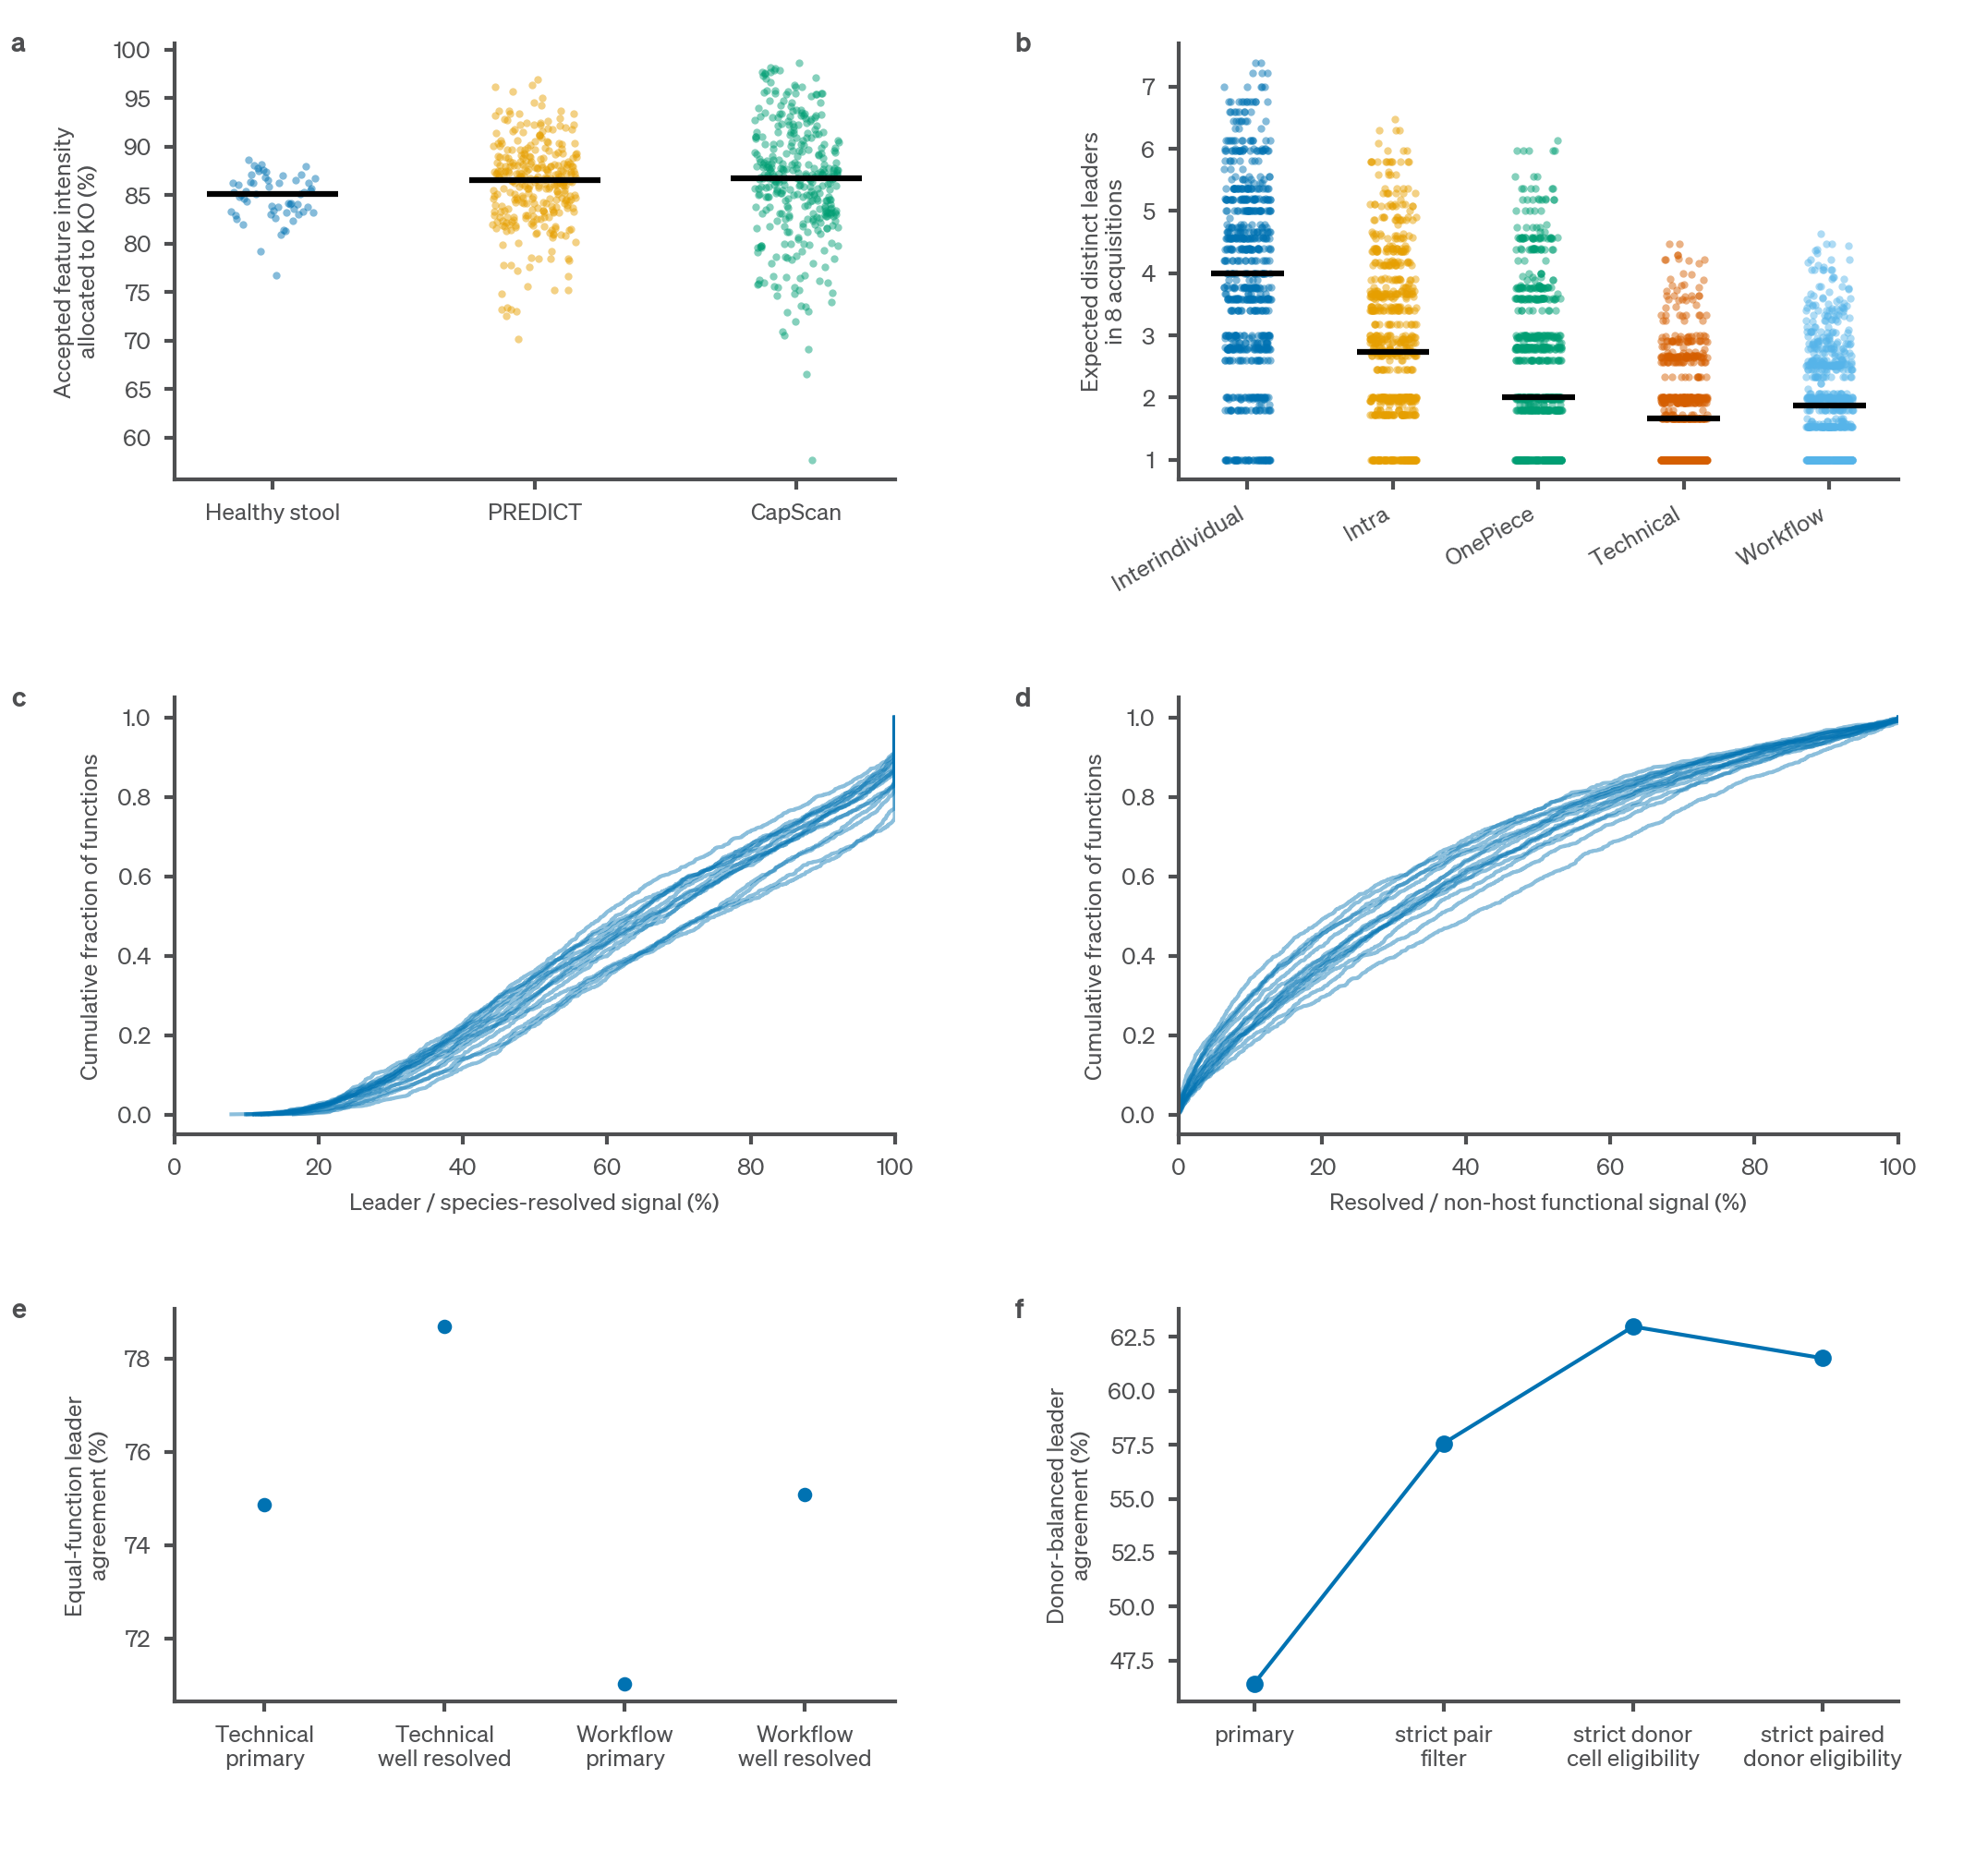

In [9]:
plotted = panels.render(t, OUT / "SFig12_v30")
plotted.to_csv(OUT / "plotted_summary_v30.tsv", sep="\t", index=False)
print("plotted summary byte-identical to the v30 build:",
      (OUT / "plotted_summary_v30.tsv").read_bytes() == (UNIT / "expected" / "plotted_summary_v30.tsv").read_bytes())
display(Image(filename=str(OUT / "SFig12_v30.png"), width=700))

## Checks and numbers

Pixel checks against the v30 figure (PNG, and PDF at 300 dpi); text pixels need the Söhne fonts. Then every recomputed number, in `NUMBERS.tsv` order.

In [10]:
from tools.check_pixels import compare
if not fl._HAVE_STYLE:
    print("pixel checks SKIPPED: fonts absent")
else:
    for new, exp, stem in [(OUT / "SFig12_v30.png", UNIT / "expected" / "SFig12_v30.png", "SFig12_v30"),
                           (OUT / "SFig12_v30.pdf", UNIT / "expected" / "SFig12_v30.pdf", "SFig12_v30_pdf")]:
        r = compare(new, exp, UNIT / "checks" / stem, dpi=300)
        print(stem, r["verdict"], "differing pixels:", r.get("differing_pixels"))

n = panels.stat_cd_counts(t["cells"])
b = panels.stat_b_depth(t["leaders"])
fr = f_new.set_index("rule")
numbers = [
    ("81", "f_primary_direct_pct", 100 * float(fr.loc["primary", "donor_balanced_agreement"])),
    ("81", "f_participants", int(fr.loc["primary", "n_donors"])),
    ("81", "f_strict_pair_direct_pct", 100 * float(fr.loc["strict_pair_filter", "donor_balanced_agreement"])),
    ("82", "median_species_resolved_pct", 100 * panels.stat_cd_median_resolved(t["cells"])),
    ("243", "rarefaction_depth_word", b["word"]),
    ("243", "cells", n["cells"]),
    ("243", "functions", n["functions"]),
    ("243", "participants", n["participants"]),
    ("402", "cells", n["cells"]),
    ("402", "functions", n["functions"]),
]
for line, key, val in numbers:
    print(f"{line}\t{key}\t{val!r}")

SFig12_v30 IDENTICAL differing pixels: 0


SFig12_v30_pdf IDENTICAL differing pixels: 0
81	f_primary_direct_pct	46.42546916329173
81	f_participants	15
81	f_strict_pair_direct_pct	57.56969912129997
82	median_species_resolved_pct	29.078817438406556
243	rarefaction_depth_word	'eight'
243	cells	21168
243	functions	1467
243	participants	15
402	cells	21168
402	functions	1467
